# This is the main notebook containing the code for producing plots in the report. 

## Species analysis

You are working for an NGO and are tasked with mapping biodiversity across the world. You have been provided with a dataset which encodes the geographic locations where different animal species have been observed. As part of the analyses into understanding what measures can be taken to help conservation efforts, there are a number of potential questions that one might consider, including:
- For any given species, where can one find them in the world?
- For a given location in the world, what and how many species may be observed there?
- Can you discover any interesting relationships between species? e.g. does the presence of one species in a location tell you about the possible presence of others?
- Can you discover any interesting relationships between species and locations? e.g. do specific species have a preference for certain habitats. 

Your goal is to take inspiration from the data analysis and machine learning algorithms we have seen in the class to create predictive models to explore questions such as, but not limited to, the ones above. The data has been processed for you in terms of train and test files already, including some additional training data if you would like to use it. Note, you should not train on the test data. A simple script that details how to load and minimally visualise this data is also included. 

Data sources:
 -  train data is from iNaturalist -  www.inaturalist.org
 -  test data is IUCN - https://www.iucnredlist.org/resources/spatial-data-download

You can find out information about each species by appending the taxon_id to this URL, e.g. for 22956: 'Leptodactylus mystacinus', the URL is: 
https://www.inaturalist.org/taxa/22956. 
Note some species might not be on the website anymore

Things to keep in mind: 
 - data has been collected by citizen scientists so it is noisy

Possible questions to explore: 
 - train a separate model to predict what locations a species of interest is present 
 - train a single model instead of per species model 
 - how to deal with "positive only data"
 - dealing with noisy/biased training data
 - using other input features e.g. climate data from  WorldClim Bioclimatic 
   variables  https://www.worldclim.org/data/worldclim21.html
 - how to evaluate e.g. what is a good metric to use?

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import geopandas as gpd
from collections import Counter
import networkx as nx
import seaborn as sns
from sklearn.metrics import accuracy_score, top_k_accuracy_score, log_loss
from scipy.stats import entropy
from sklearn.cluster import KMeans
from sklearn.naive_bayes import GaussianNB
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from math import sqrt

In [4]:
path = "../data/"

In [5]:
species_lookup = pd.read_csv(path + 'species_lookup.csv')
print(species_lookup.shape)

train_df = pd.read_csv(path + 'train_df.csv')
print(train_df.shape)

test_df = pd.read_csv(path + 'test_df.csv')
print(test_df.shape)

train_gdf_joined = gpd.read_parquet(path + "train_gdf_joined.parquet")
print(train_gdf_joined.shape)

test_gdf_joined = gpd.read_parquet(path + "test_gdf_joined.parquet")
print(test_gdf_joined.shape)

(500, 2)
(272037, 3)
(1706646, 3)
(283958, 35)
(1726886, 35)


## Species-species relationships

In [6]:
# combining train and test for exploratory analysis
df = pd.concat([train_df, test_df], ignore_index=True)
df["lat_bin"] = df["latitude"].round(2)
df["lon_bin"] = df["longitude"].round(2)

# grouping by approximate locations
locgroups = df.groupby(["lat_bin", "lon_bin"])["taxon_id"].apply(set)

# building co-occurrence counts (representation of co-occurence matrix)
pair_counter = Counter()
species_counter = Counter()

for species_set in locgroups:
    species_list = list(species_set)
    for i in range(len(species_list)):
        species_counter[species_list[i]] += 1
        for j in range(i + 1, len(species_list)):
            pair = tuple(sorted([species_list[i], species_list[j]]))
            pair_counter[pair] += 1

cooccurences = pd.DataFrame([
    (s1, s2, c) for (s1, s2), c in pair_counter.items()
], columns=["species_1", "species_2", "coocc_count"])

# computing PMI - pointwise mutual information
def pmi(s1, s2):
    pair = tuple(sorted([s1, s2]))
    co = pair_counter[pair]
    if co == 0: 
        return 0
    p_xy = co / total_loc
    p_x = species_counter[s1] / total_loc
    p_y = species_counter[s2] / total_loc
    return np.log(p_xy / (p_x * p_y))

total_loc = len(locgroups)
cooccurences["pmi"] = cooccurences.apply(lambda r: pmi(r["species_1"], r["species_2"]), axis=1)
sorted_species_links = cooccurences.sort_values("pmi", ascending=False)

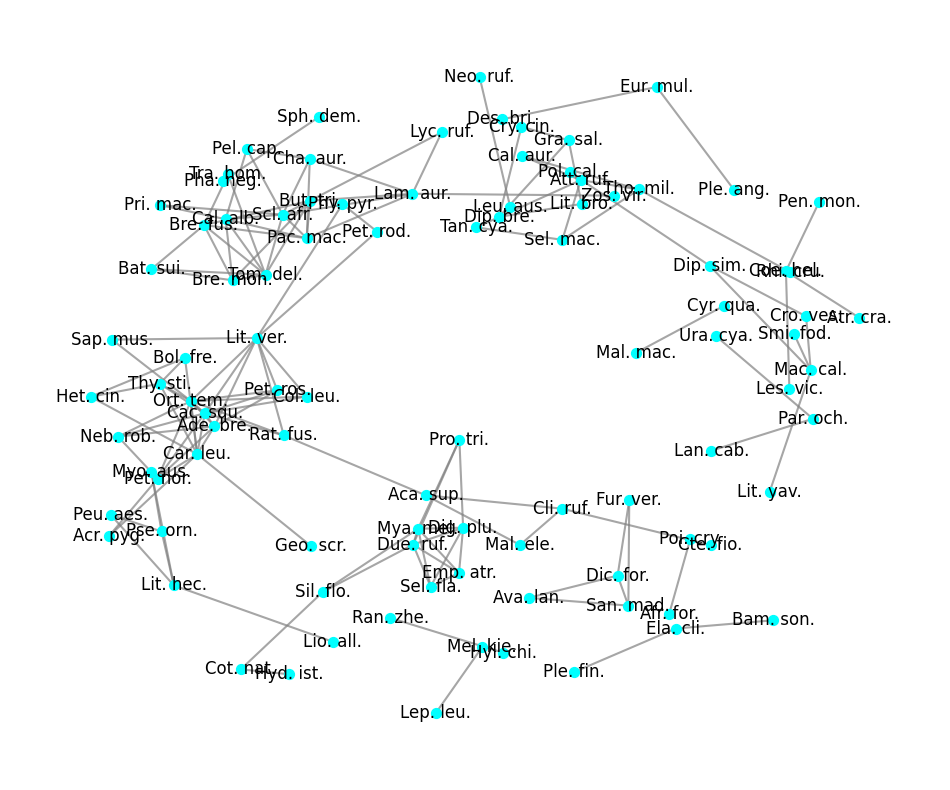

In [7]:
threshold = 6.0
strong_links = cooccurences[cooccurences["pmi"] > threshold]
taxon_lookup = dict(zip(species_lookup['taxon_id'], species_lookup['taxon_name']))

graph = nx.Graph()
for _, row in strong_links.iterrows():
    s1, s2 = row["species_1"], row["species_2"]
    graph.add_edge(taxon_lookup[s1], taxon_lookup[s2], weight=row["pmi"])

plt.figure(figsize=(12, 10))
pos = nx.spring_layout(graph, k=0.7, seed=42)

nx.draw_networkx_nodes(graph, pos, node_size=50, node_color="aqua")
nx.draw_networkx_edges(graph, pos, width=1.5, alpha=0.7, edge_color="grey")
# nx.draw_networkx_labels(G, pos, font_size=8)
nx.draw_networkx_labels(graph, pos, labels={node: str(node).split(" ")[0][:3] + ". " + str(node).split(" ")[1][:3] + "." for node in graph.nodes()}, font_size=12)

# plt.title(f"Species co-occurrence network graph (only edges with PMI > {threshold} are displayed)")
plt.axis("off")
plt.show()

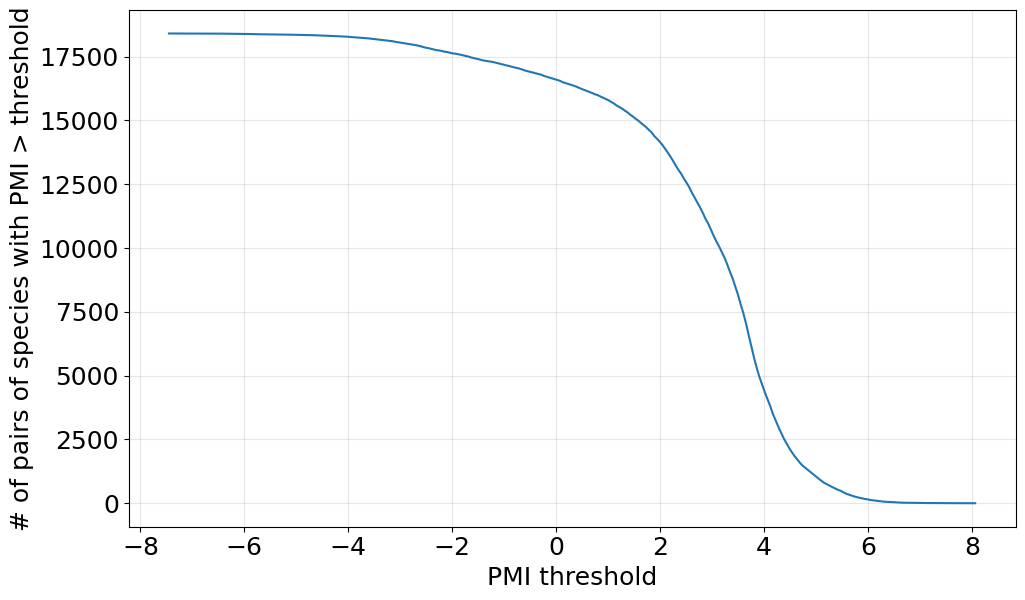

In [8]:
pmi_values = cooccurences["pmi"].values

# creating a grid of PMI thresholds
pmis_sorted = np.sort(pmi_values)
thresholds = np.linspace(pmis_sorted.min(), pmis_sorted.max(), 300)

cumulat_counts = [(pmi_values >= t).sum() for t in thresholds]

plt.figure(figsize=(10, 6))
plt.plot(thresholds, cumulat_counts)
# plt.title("Cumulative number of pairs of species exceeding PMI threshold")
plt.xlabel("PMI threshold", fontsize=18)
plt.ylabel("# of pairs of species with PMI > threshold", fontsize=18)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.xticks(fontsize=18)
plt.yticks(fontsize=18)
plt.show()

## Species-location relationships

In [13]:
# clustering + per-species habitat preference
coords = df[["latitude", "longitude"]].values
scaler = StandardScaler()
coords_scaled = scaler.fit_transform(coords)

n = 12
km = KMeans(n_clusters=n, random_state=42)
df["cluster"] = km.fit_predict(coords_scaled)

cluster_frequensy = (df.groupby(["taxon_id", "cluster"]).size().reset_index(name="count"))

# identifying species with strongest habitat preference
species_total = df.groupby("taxon_id").size().rename("total")
cluster_frequensy = cluster_frequensy.merge(species_total, on="taxon_id")
cluster_frequensy["cluster_pref_score"] = cluster_frequensy["count"] / cluster_frequensy["total"]

strong_preferences = (cluster_frequensy.sort_values("cluster_pref_score", ascending=False).groupby("taxon_id")
                      .head(1).sort_values("cluster_pref_score", ascending=False))
print(strong_preferences.tail(30))

     taxon_id  cluster  count   total  cluster_pref_score
309     12821        5   1138    2269            0.501543
409     16972       10   4389    8752            0.501485
714     47107       10   3769    7616            0.494879
266     11970        9   4285    8706            0.492189
404     16782        1   5628   11900            0.472941
717     54549       11   9722   20562            0.472814
853    204544        2   1309    2782            0.470525
442     19975       10   5222   11207            0.465959
232      9771        1   7555   16318            0.462986
68       4191       11  19729   43438            0.454188
228      9639        2   8420   18712            0.449979
602     40523        1   5610   12678            0.442499
920    855311        5   3552    8037            0.441956
354     13851        2  11356   25943            0.437729
844    201178        5   2841    6505            0.436741
394     15302        7  12166   28523            0.426533
398     16079 

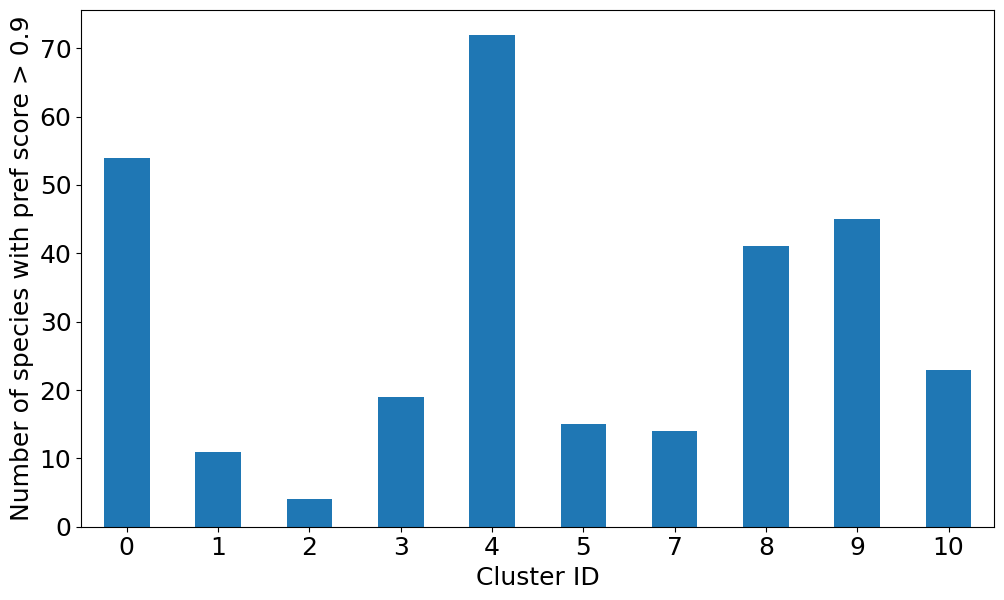

In [14]:
plt.figure(figsize=(10,6))
specialists_per_cluster = strong_preferences[strong_preferences['cluster_pref_score'] > 0.9].groupby("cluster").size()
specialists_per_cluster.plot(kind="bar")
# plt.title(f"Number of specialist species per habitat cluster ({specialists_per_cluster.sum()} total)")
plt.xlabel("Cluster ID", fontsize=18)
plt.ylabel("Number of species with pref score > 0.9", fontsize=18)
plt.xticks(rotation=0)
plt.tight_layout()
plt.xticks(fontsize=18)
plt.yticks(fontsize=18)
plt.show()

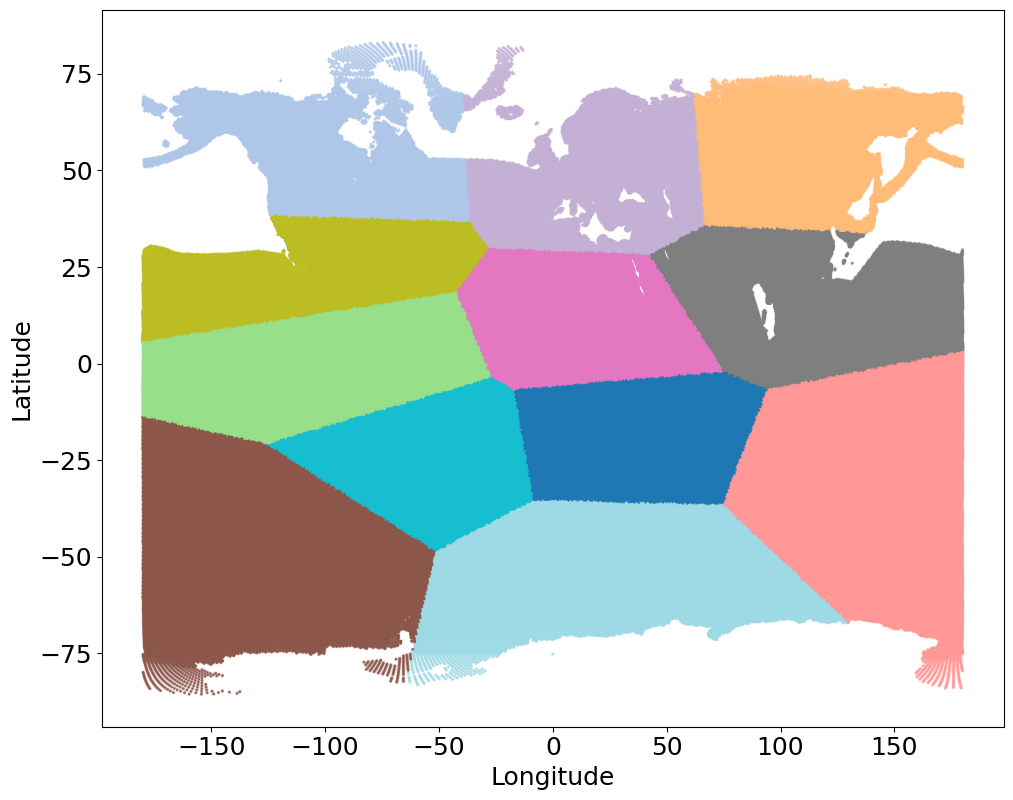

In [15]:
plt.figure(figsize=(10,8))
scatter = plt.scatter(df["longitude"], df["latitude"], c=df["cluster"], s=5, alpha=0.1, cmap="tab20")

# overlaying specialists as larger points
specialists_t = strong_preferences["taxon_id"].unique()
df_specialists = df[df["taxon_id"].isin(specialists_t)]

plt.scatter(df_specialists["longitude"], df_specialists["latitude"], c=df_specialists["cluster"], s=1, alpha=0.8, cmap="tab20")
# plt.title("Spatial distribution of habitat specialist species")
plt.xlabel("Longitude", fontsize=18)
plt.ylabel("Latitude", fontsize=18)
# plt.colorbar(scatter, label="Cluster ID")
plt.tight_layout()
plt.xticks(fontsize=18)
plt.yticks(fontsize=18)
plt.show()

## Spatial variance of individual species using probabilistic modeling (per-species Naive Bayes model)

In [ ]:
results = []

for species_id in df["taxon_id"].unique():
    df_copy = df.copy()
    df_copy["is_species"] = (df_copy["taxon_id"] == species_id).astype(int)

    X = df_copy[["latitude", "longitude"]].values
    y = df_copy["is_species"].values

    model = GaussianNB()
    model.fit(X, y)

    var = model.var_.mean()
    results.append((species_id, var))

specialisation_df = pd.DataFrame(results, columns=["taxon_id", "avg_location_variance"])
specialisation_df = specialisation_df.sort_values("avg_location_variance")

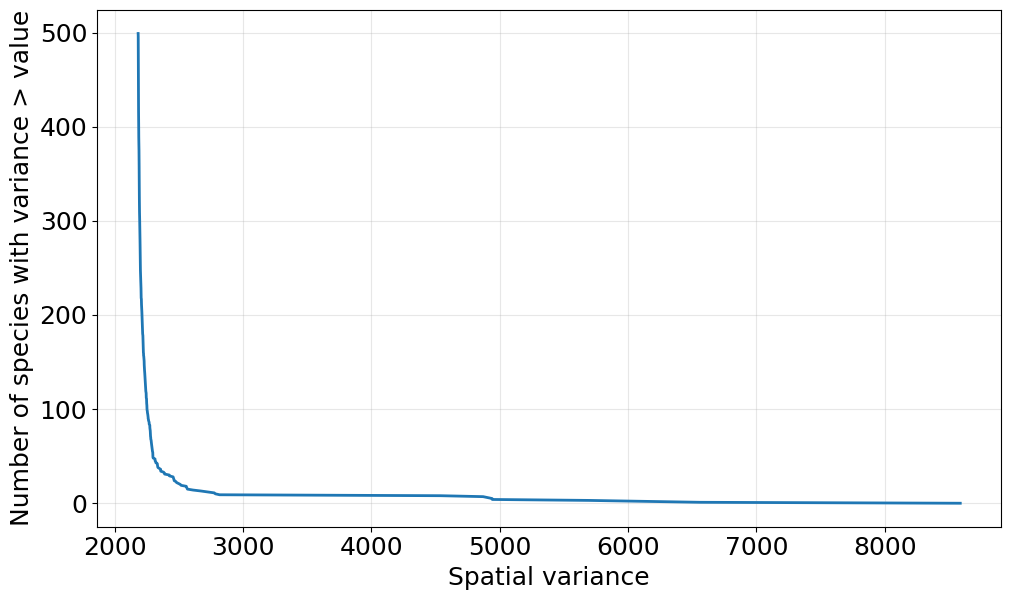

In [ ]:
specialisation_df_sorted = specialisation_df.sort_values("avg_location_variance").reset_index(drop=True)

plt.figure(figsize=(10,6))
plt.plot(specialisation_df_sorted["avg_location_variance"], 500 - np.arange(1, len(specialisation_df_sorted) + 1), linewidth=2)
plt.xlabel("Spatial variance", fontsize=18)
plt.ylabel("Number of species with variance > value", fontsize=18)
# plt.title("Cumulative distribution of geographic variance across species")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.xticks(fontsize=18)
plt.yticks(fontsize=18)
plt.show()

## Exploratory data analysis with conservation features

In [20]:
train_gdf_joined["inside_protected_area"] = (~train_gdf_joined["WDPAID"].isna()).astype(int)

print(f"Observations: {len(train_gdf_joined)}") # 283958
print(f"Of them inside protected areas: {train_gdf_joined['inside_protected_area'].sum()} ({train_gdf_joined['inside_protected_area'].sum() / len(train_gdf_joined) * 100.0:.2f}%)") # 57092 (20.11%)
print(f"Unique species: {train_gdf_joined['taxon_id'].nunique()}") # 500
print(f"Of them inside protected areas: {train_gdf_joined[train_gdf_joined['inside_protected_area'] == 1]['taxon_id'].nunique()}") # 487
print("Top 10 most observed species:")
print(train_gdf_joined["taxon_id"].value_counts().head(10))
print()

species_protected = (train_gdf_joined.groupby("taxon_id")["inside_protected_area"].agg(n_obs="size", n_inside="sum", prop_inside="mean").reset_index().sort_values("prop_inside", ascending=False))

print("Sample of species with highest proportion of records inside protected areas:")
print(species_protected.head(10).to_string(index=False))
print()
print("Sample of species with lowest proportion of records inside protected areas:")
print(species_protected.tail(10).to_string(index=False))
print()
print(f"Species with > 50% of observations inside protected areas: {(species_protected['prop_inside'] > 0.5).sum()} ({(species_protected['prop_inside'] > 0.5).sum() / train_gdf_joined['taxon_id'].nunique():.2%})") # 29 (5.80%)
print()

Observations: 283958
Of them inside protected areas: 57092 (20.11%)
Unique species: 500
Of them inside protected areas: 487
Top 10 most observed species:
taxon_id
31150     2514
4208      2477
343021    2446
27726     2443
12038     2363
26159     2355
12735     2334
472766    2277
4345      2250
144243    2171
Name: count, dtype: int64

Sample of species with highest proportion of records inside protected areas:
 taxon_id  n_obs  n_inside  prop_inside
    16623     91        82     0.901099
    12953    172       146     0.848837
     6364    261       220     0.842912
     9832    222       176     0.792793
    32861     60        47     0.783333
    35854   1767      1207     0.683079
    24994     92        62     0.673913
   558436    568       373     0.656690
    33142    122        78     0.639344
     4191    131        82     0.625954

Sample of species with lowest proportion of records inside protected areas:
 taxon_id  n_obs  n_inside  prop_inside
    43530     90         0

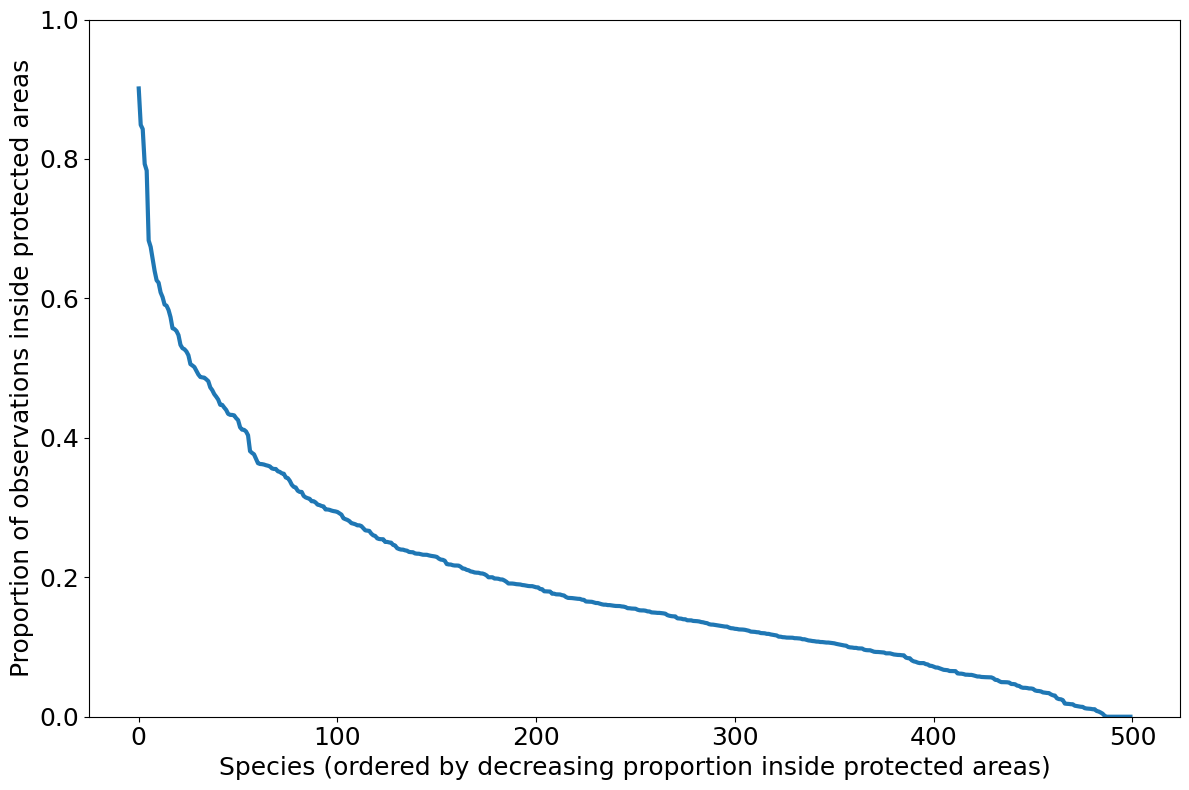

In [21]:
plt.figure(figsize=(12,8))
sns.lineplot(x=range(len(species_protected)), y="prop_inside", data=species_protected, marker="", linewidth=3)
plt.xlabel("Species (ordered by decreasing proportion inside protected areas)", fontsize=18)
plt.ylabel("Proportion of observations inside protected areas", fontsize=18)
# plt.title("Per-species proportion of observations inside protected areas")
plt.ylim(0, 1)
plt.xticks(fontsize=18)
plt.yticks(fontsize=18)
plt.tight_layout()
plt.show()

## Modelling

In [ ]:
X_train = train_df[["latitude", "longitude"]].values
y_train = train_df["taxon_id"].values
X_test = test_df[["latitude", "longitude"]].values
y_test = test_df["taxon_id"].values

# using softmax multiclass model (logistic regression) 
model = Pipeline([
    ("scaler", StandardScaler()),
    ("clf", LogisticRegression(multi_class="multinomial", max_iter=500, solver="lbfgs"))
])

print("Training")
model.fit(X_train, y_train)

In [ ]:
probs_test = model.predict_proba(X_test)
pred_test = model.predict(X_test)

acc = accuracy_score(y_test, pred_test)
top3 = top_k_accuracy_score(y_test, probs_test, k=3)
top5 = top_k_accuracy_score(y_test, probs_test, k=5)
ll = log_loss(y_test, probs_test)

print("Species prediction performance")
print(f"Top-1 accuracy:        {acc:.4f}")    # 0.0464
print(f"Top-3 accuracy:        {top3:.4f}")   # 0.1067
print(f"Top-5 accuracy:        {top5:.4f}")   # 0.1627
print(f"Log-loss:              {ll:.4f}\n")   # 6.7815

In [ ]:
max_probs = probs_test.max(axis=1)

In [ ]:
entropies = entropy(probs_test.T)

# low entropy = strongly peaked distribution, high entropy = uniform-like distribution
print("Probability distribution shape")
print(f"Mean entropy:          {entropies.mean():.4f}")  # 3.6522
print(f"Min entropy:           {entropies.min():.4f}")   # 0.0011
print(f"Max entropy:           {entropies.max():.4f}\n") # 4.8276

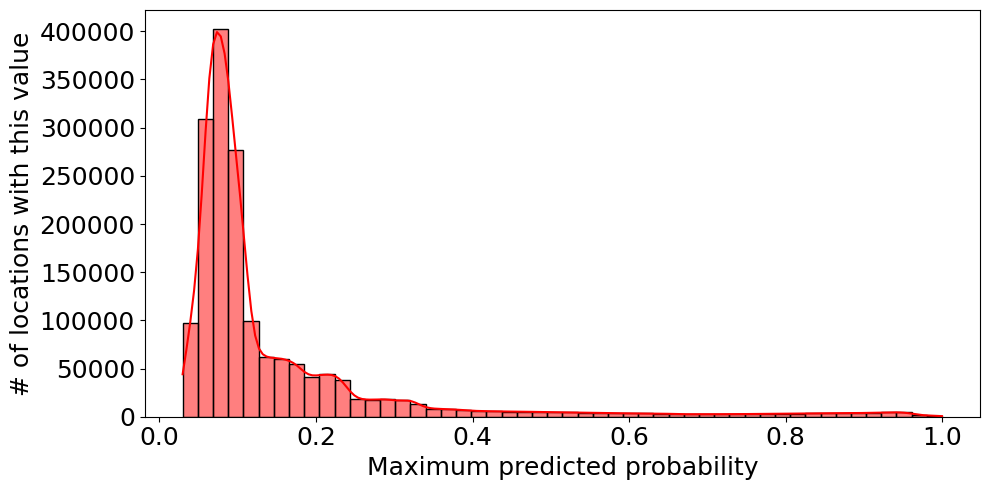

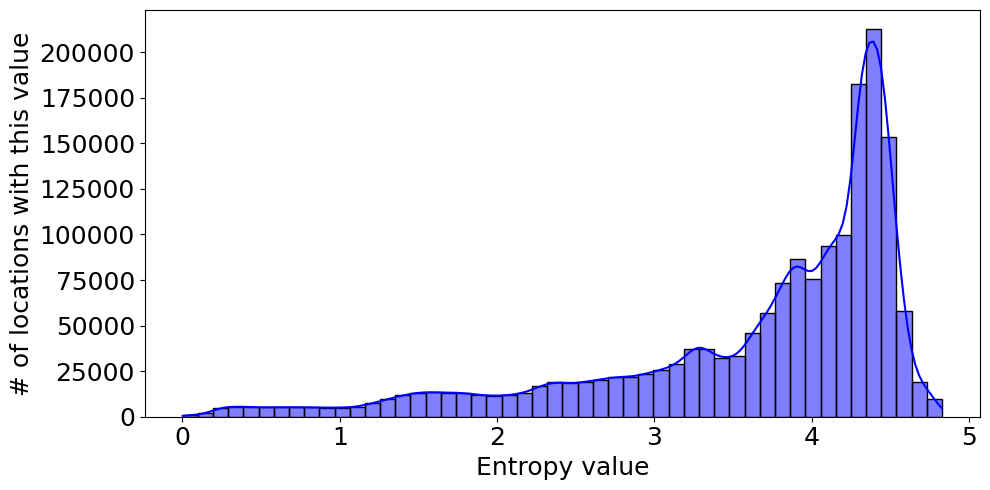

In [ ]:
plt.figure(figsize=(10,5))
sns.histplot(max_probs, bins=50, kde=True, color='red')
# plt.title("Distribution of maximum predicted probability per location")
plt.xlabel("Maximum predicted probability", fontsize=18)
plt.ylabel("# of locations with this value", fontsize=18)
plt.xticks(fontsize=18)
plt.yticks(fontsize=18)
plt.tight_layout()
plt.show()

plt.figure(figsize=(10,5))
sns.histplot(entropies, bins=50, kde=True, color='blue')
# plt.title("Distribution of probability entropies across locations")
plt.xlabel("Entropy value", fontsize=18)
plt.ylabel("# of locations with this value", fontsize=18)
plt.xticks(fontsize=18)
plt.yticks(fontsize=18)
plt.tight_layout()
plt.show()